In [1]:
import numpy as np
import QuantLib as ql

def heston_price(S, K, T, r, kappa, theta, sigma, rho, v0):
    """
    Prices a European call option under the Heston model.
    
    S     = current stock price (e.g., 100)
    K     = strike price (e.g., 105)
    T     = time to maturity in years (e.g., 1.0)
    r     = risk-free rate (e.g., 0.03)
    kappa = mean reversion speed
    theta = long-run variance
    sigma = volatility of volatility
    rho   = correlation between stock and variance
    v0    = initial variance
    
    Returns: the call option price (a single number)
    """
    
    # 1. Set the valuation date (today) and calculate the maturity date
    today = ql.Date(1, 1, 2025)
    ql.Settings.instance().evaluationDate = today
    maturity_date = today + ql.Period(round(T * 365), ql.Days)
    
    # 2. Define the option: European call with strike K, expiring at maturity_date
    option_type = ql.Option.Call
    payoff = ql.PlainVanillaPayoff(option_type, K)
    exercise = ql.EuropeanExercise(maturity_date)
    option = ql.VanillaOption(payoff, exercise)
    
    # 3. Set up the market: spot price, risk-free rate, and dividend yield (0)
    spot_handle = ql.QuoteHandle(ql.SimpleQuote(S))
    rate_handle = ql.YieldTermStructureHandle(
        ql.FlatForward(today, r, ql.Actual365Fixed())
    )
    dividend_handle = ql.YieldTermStructureHandle(
        ql.FlatForward(today, 0.0, ql.Actual365Fixed())
    )
    
    # 4. Set up the Heston process with our 5 parameters
    heston_process = ql.HestonProcess(
        rate_handle, dividend_handle, spot_handle,
        v0,      # initial variance
        kappa,   # mean reversion speed
        theta,   # long-run variance
        sigma,   # vol of vol
        rho      # correlation
    )
    
    # 5. Create the Heston model and pricing engine
    heston_model = ql.HestonModel(heston_process)
    engine = ql.AnalyticHestonEngine(heston_model)
    
    # 6. Attach the engine to the option and compute the price
    option.setPricingEngine(engine)
    
    return option.NPV()  # NPV = Net Present Value = the option price


# TEST IT
price = heston_price(
    S=100,       # stock price is 100
    K=100,       # strike is 100 (at-the-money)
    T=1.0,       # 1 year to expiry
    r=0.03,      # 3% risk-free rate
    kappa=2.0,   # mean reversion speed
    theta=0.04,  # long-run variance (implies ~20% long-run volatility)
    sigma=0.5,   # vol of vol
    rho=-0.7,    # negative correlation (leverage effect)
    v0=0.04      # initial variance (implies ~20% current volatility)
)

print(f"Heston call price: {price:.4f}")

Heston call price: 8.9294


In [2]:
heston_price(S=100, K=100, T=5, r=0.03,
             kappa=2.0, theta=0.04, sigma=0.5, rho=-0.7, v0=0.04)

23.997235912169916

In [3]:
# VERIFICATION: When sigma=0.001 and rho=0, Heston should match Black-Scholes
from scipy.stats import norm
import numpy as np

# Black-Scholes formula
S, K, T, r, vol = 100, 100, 1.0, 0.03, 0.20

d1 = (np.log(S/K) + (r + 0.5*vol**2)*T) / (vol*np.sqrt(T))
d2 = d1 - vol*np.sqrt(T)
bs_price = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

# Heston with almost zero vol-of-vol (sigma near 0 makes variance nearly constant)
heston_test = heston_price(S=100, K=100, T=1.0, r=0.03,
                           kappa=2.0, theta=0.04, sigma=0.001, rho=0.0, v0=0.04)

print(f"Black-Scholes price: {bs_price:.4f}")
print(f"Heston price:        {heston_test:.4f}")
print(f"Difference:          {abs(bs_price - heston_test):.6f}")

Black-Scholes price: 9.4134
Heston price:        9.4134
Difference:          0.000002


In [4]:
import numpy as np
import pandas as pd
from scipy.stats import qmc, norm
from scipy.optimize import brentq

# STEP 3: GENERATE SYNTHETIC TRAINING DATA

# --- Helper: Black-Scholes price (needed to convert Heston prices to implied vol) ---
def bs_call_price(S, K, T, r, sigma):
    """Black-Scholes call price given volatility sigma."""
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


# --- Helper: Find implied volatility from a given option price ---
def implied_vol(price, S, K, T, r):
    """
    Given a market (or Heston) price, find the BS implied volatility.
    Uses brentq: a root-finding method that searches for the sigma
    where bs_call_price(sigma) = price.
    """
    try:
        iv = brentq(lambda sigma: bs_call_price(S, K, T, r, sigma) - price,
                     0.01, 5.0)  # search between 1% and 500% vol
        return iv
    except:
        return np.nan  # return NaN if it fails


# --- Define the strike and maturity grid ---
S = 100       # spot price (fixed for synthetic data)
r = 0.03      # risk-free rate (fixed)

# 10 strikes: from 80% to 120% of spot price
moneyness = [0.80, 0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.15, 1.20, 1.25]
strikes = [S * m for m in moneyness]

# 7 maturities: from 1 month to 2 years
maturities = [30/365, 91/365, 182/365, 274/365, 365/365, 548/365, 730/365] #maturities rewritten as whole days so the pricer and implied-vol agree on time to expiry

print(f"Grid: {len(strikes)} strikes x {len(maturities)} maturities = {len(strikes)*len(maturities)} options per sample")
print(f"Strikes: {strikes}")
print(f"Maturities: {maturities}")

Grid: 10 strikes x 7 maturities = 70 options per sample
Strikes: [80.0, 85.0, 90.0, 95.0, 100.0, 105.0, 110.00000000000001, 114.99999999999999, 120.0, 125.0]
Maturities: [0.0821917808219178, 0.2493150684931507, 0.4986301369863014, 0.7506849315068493, 1.0, 1.5013698630136987, 2.0]


In [5]:
today = ql.Date(1, 1, 2025)
ql.Settings.instance().evaluationDate = today

spot_handle = ql.QuoteHandle(ql.SimpleQuote(S))
rate_handle = ql.YieldTermStructureHandle(ql.FlatForward(today, r, ql.Actual365Fixed()))
dividend_handle = ql.YieldTermStructureHandle(ql.FlatForward(today, 0.0, ql.Actual365Fixed()))
option_type = ql.Option.Call

In [6]:
options_list = []
for T in maturities:
    for K in strikes:
        maturity_date = today + ql.Period(round(T * 365), ql.Days)
        payoff = ql.PlainVanillaPayoff(option_type, K)
        exercise = ql.EuropeanExercise(maturity_date)
        option = ql.VanillaOption(payoff, exercise)
        options_list.append((option, K, T))

In [7]:
def surface_for(kappa, theta, sigma, rho, v0):
    heston_process = ql.HestonProcess(
        rate_handle, dividend_handle, spot_handle,
        v0, kappa, theta, sigma, rho
    )
    heston_model =ql.HestonModel(heston_process)
    engine = ql.AnalyticHestonEngine(heston_model)

    results = []
    for option, K, T in options_list:
        option.setPricingEngine(engine)
        price = option.NPV()
        iv =  implied_vol(price, S, K, T, r)
        results.append(iv)

    return results

In [8]:

# SAMPLE HESTON PARAMETERS AND GENERATE DATA

N_SAMPLES = 20000

# --- Step 1: Sample parameter combinations using Latin Hypercube Sampling ---
# LHS ensures even coverage of the parameter space
sampler = qmc.LatinHypercube(d=5)  # d=5 because we have 5 parameters
samples_unit = sampler.random(n=N_SAMPLES)  # values between 0 and 1

# --- Step 2: Scale to our parameter ranges ---
# Each column corresponds to: kappa, theta, sigma, rho, v0
lower_bounds = [0.5,  0.01, 0.1,  -0.95, 0.01]  # minimum values
upper_bounds = [10.0, 0.15, 1.0,  -0.10, 0.15]  # maximum values

# Scale from [0,1] to [lower, upper] for each parameter
samples_scaled = qmc.scale(samples_unit, lower_bounds, upper_bounds)

# Check: print first 3 samples
print("First 3 parameter sets:")
print(f"{'kappa':>8} {'theta':>8} {'sigma':>8} {'rho':>8} {'v0':>8}")
for i in range(3):
    kappa, theta, sigma, rho, v0 = samples_scaled[i]
    print(f"{kappa:8.3f} {theta:8.4f} {sigma:8.3f} {rho:8.3f} {v0:8.4f}")

First 3 parameter sets:
   kappa    theta    sigma      rho       v0
   8.403   0.1434    0.533   -0.658   0.0301
   5.044   0.0194    0.963   -0.389   0.1403
   9.146   0.0492    0.868   -0.293   0.1107


In [9]:
# GENERATE OR LOAD THE DATASET
# Generates only if the data file is not already on disk.

import os
import time

if os.path.exists(f'X_{N_SAMPLES}.npy'):
    X = np.load(f'X_{N_SAMPLES}.npy')
    y = np.load(f'y_{N_SAMPLES}.npy')
    print(f"Loaded from disk: X{X.shape}, y{y.shape}")

else:
    print(f"No saved data found. Generating {N_SAMPLES} samples...")

    all_ivs = []       # implied volatility surfaces (inputs for XGBoost)
    all_params = []    # Heston parameters (targets for XGBoost)
    failed = 0

    start_time = time.time()

    for i in range(N_SAMPLES):

        kappa, theta, sigma, rho, v0 = samples_scaled[i]

        iv_surface = []
        success = True

        for T in maturities:
            for K in strikes:
                try:
                    price = heston_price(S, K, T, r, kappa, theta, sigma, rho, v0)
                    iv = implied_vol(price, S, K, T, r)

                    if np.isnan(iv) or iv <= 0 or iv > 3.0:
                        print("rejected: iv =", iv, "| K =", K, "| T =", T,
                              "| v0 =", v0, "| rho =", rho)
                        success = False
                        break

                    iv_surface.append(iv)

                except Exception as e:
                    print(e)
                    success = False
                    break

            if not success:
                break

        if success and len(iv_surface) == 70:
            all_ivs.append(iv_surface)
            all_params.append([kappa, theta, sigma, rho, v0])
        else:
            failed += 1

        if (i + 1) % 500 == 0:
            elapsed = time.time() - start_time
            print(f"Sample {i+1}/{N_SAMPLES} | {len(all_ivs)} good | "
                  f"{failed} failed | {elapsed:.0f}s")
            np.save('X_partial.npy', np.array(all_ivs))
            np.save('y_partial.npy', np.array(all_params))

    elapsed = time.time() - start_time
    print(f"\nFinished: {len(all_ivs)} successful, {failed} failed, {elapsed:.0f}s")

    X = np.array(all_ivs)
    y = np.array(all_params)
    np.save(f'X_{N_SAMPLES}.npy', X)
    np.save(f'y_{N_SAMPLES}.npy', y)
    print(f"Saved: X{X.shape}, y{y.shape}")

Loaded from disk: X(19892, 70), y(19892, 5)


In [10]:

# STEP 4: TRAIN XGBOOST MODELS


from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# --- Split the data: 70% train, 15% validation, 15% test ---
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.176, random_state=42
)
# 0.176 of 85% ≈ 15% of total

print(f"Training set:   {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set:       {X_test.shape[0]} samples")

Training set:   13932 samples
Validation set: 2976 samples
Test set:       2984 samples


In [11]:

# TRAIN 5 XGBOOST MODELS (one per parameter)


param_names = ['kappa', 'theta', 'sigma', 'rho', 'v0']

# Store the trained models and results
models = {}
results = {}

for i, name in enumerate(param_names):
    
    print(f"\nTraining model for: {name}")
    
    # Create the XGBoost model
    model = xgb.XGBRegressor(
        n_estimators=1000,      # up to 1000 trees
        max_depth=6,            # each tree has max 6 levels
        learning_rate=0.05,     # small steps for better accuracy
        subsample=0.8,          # use 80% of data per tree (reduces overfitting)
        colsample_bytree=0.8,   # use 80% of features per tree
        early_stopping_rounds=50,  # stop if no improvement for 50 rounds
        random_state=42
    )
    
    # Train: learns from X_train, monitors progress on X_val
    model.fit(
        X_train, y_train[:, i],           # training data
        eval_set=[(X_val, y_val[:, i])],  # validation data for monitoring
        verbose=False                      # don't print every round
    )
    
    # Predict on test set
    y_pred = model.predict(X_test)
    y_true = y_test[:, i]
    
    # Calculate accuracy metrics
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # Store
    models[name] = model
    results[name] = {'MAE': mae, 'MSE': mse, 'R2': r2}
    
    print(f"  MAE = {mae:.4f}")
    print(f"  MSE = {mse:.6f}")
    print(f"  R2  = {r2:.4f}")

print("\n--- DONE ---")


Training model for: kappa
  MAE = 0.5521
  MSE = 0.610134
  R2  = 0.9167

Training model for: theta
  MAE = 0.0013
  MSE = 0.000008
  R2  = 0.9949

Training model for: sigma
  MAE = 0.0290
  MSE = 0.001434
  R2  = 0.9791

Training model for: rho
  MAE = 0.0346
  MSE = 0.003339
  R2  = 0.9444

Training model for: v0
  MAE = 0.0008
  MSE = 0.000001
  R2  = 0.9992

--- DONE ---


In [12]:
# ============================================
# RESULTS TABLE (for Section 6 of thesis)
# ============================================

print("=" * 55)
print(f"{'Parameter':<12} {'MAE':<12} {'MSE':<14} {'R²':<10}")
print("=" * 55)
for name in param_names:
    metrics = results[name]
    print(f"{name:<12} {metrics['MAE']:<12.4f} {metrics['MSE']:<14.6f} {metrics['R2']:<10.4f}")
print("=" * 55)

Parameter    MAE          MSE            R²        
kappa        0.5521       0.610134       0.9167    
theta        0.0013       0.000008       0.9949    
sigma        0.0290       0.001434       0.9791    
rho          0.0346       0.003339       0.9444    
v0           0.0008       0.000001       0.9992    


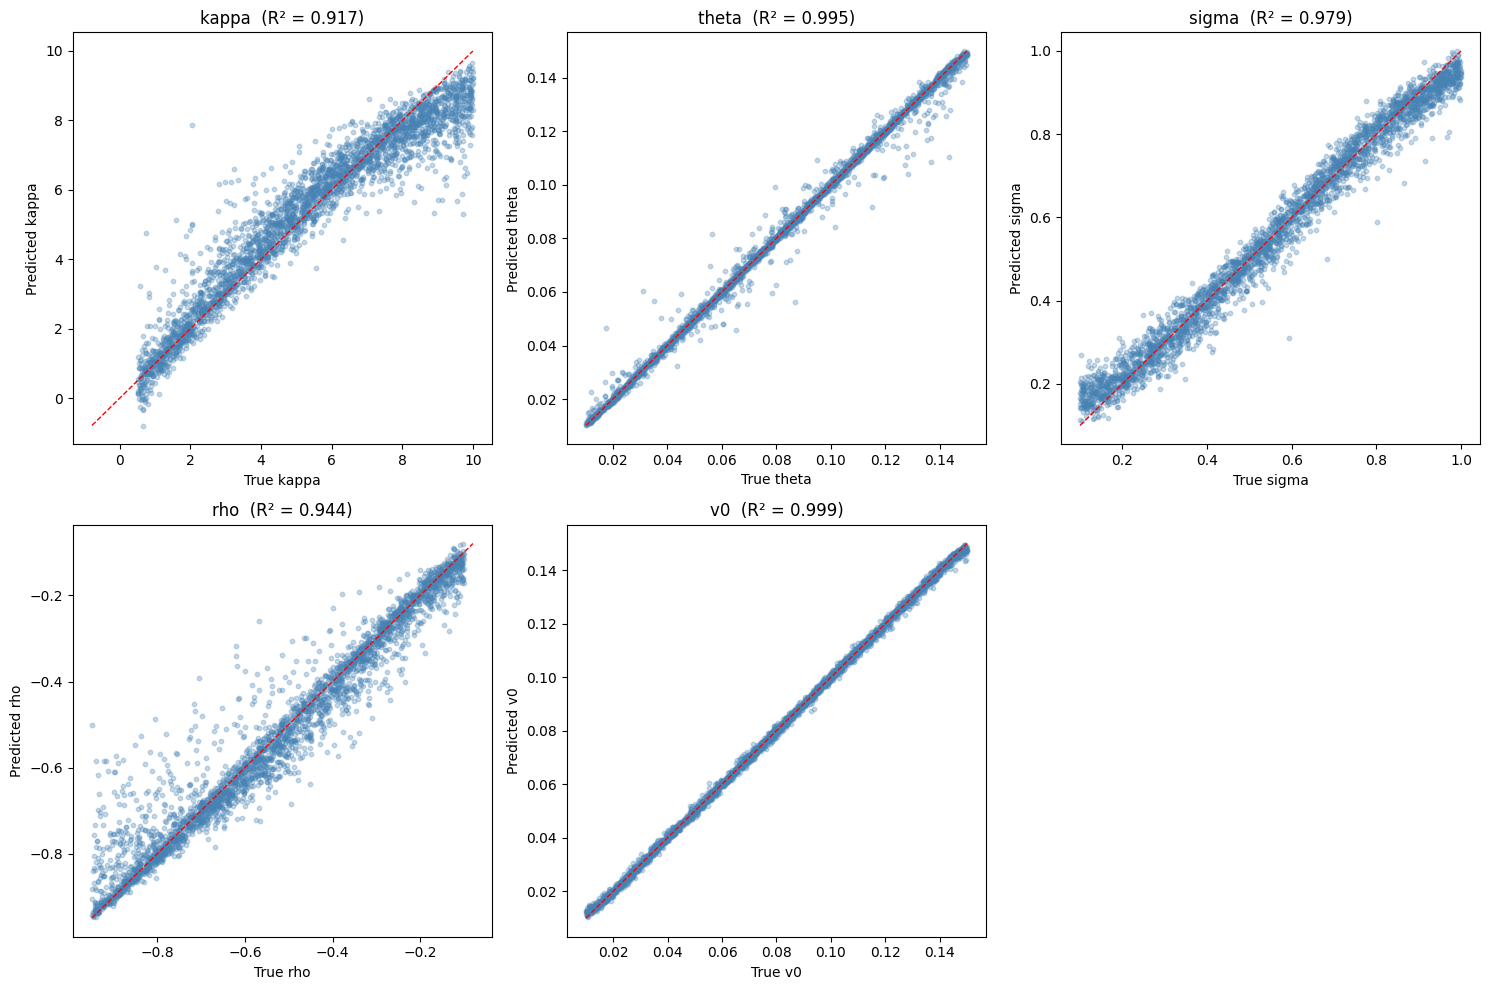

Saved: scatter_plots.png


In [13]:

# SCATTER PLOTS: Predicted vs True values

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, name in enumerate(param_names):
    ax = axes[i]
    y_true = y_test[:, i]
    y_pred = models[name].predict(X_test)
    
    ax.scatter(y_true, y_pred, alpha=0.3, s=10, color='steelblue')
    
    # Draw the perfect prediction line
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1)
    
    ax.set_xlabel(f'True {name}')
    ax.set_ylabel(f'Predicted {name}')
    ax.set_title(f'{name}  (R² = {results[name]["R2"]:.3f})')

# Hide the 6th subplot (we only have 5 parameters)
axes[5].set_visible(False)

plt.tight_layout()
plt.savefig('scatter_plots.png', dpi=150)
plt.show()
print("Saved: scatter_plots.png")

In [19]:

# STEP 5: TRADITIONAL CALIBRATION BENCHMARK


from scipy.optimize import differential_evolution
import time

def calibration_error(params, target_ivs, S, r, strikes, maturities):
    """
    Objective function: sum of squared errors between
    Heston implied vols and target implied vols.
    """
    kappa, theta, sigma, rho, v0 = params
    
    model_ivs = []
    for T in maturities:
        for K in strikes:
            try:
                price = heston_price(S, K, T, r, kappa, theta, sigma, rho, v0)
                iv = implied_vol(price, S, K, T, r)
                if np.isnan(iv):
                    return 1e6  # big penalty if pricing fails
                model_ivs.append(iv)
            except Exception as e:
                print (e)
                return 1e6
    
    # Sum of squared differences
    error = np.sum((np.array(model_ivs) - np.array(target_ivs))**2)
    return error


# --- Test on 5 samples from the test set ---
# (full calibration on all 615 would take hours)

n_test = 5
bounds = [(0.5, 10), (0.01, 0.15), (0.1, 1.0), (-0.95, -0.1), (0.01, 0.15)]

print("Comparing XGBoost vs Traditional Calibration")
print("=" * 70)

xgb_times = []
trad_times = []
xgb_errors = []
trad_errors = []

for j in range(n_test):
    target_ivs = X_test[j]   # the IV surface to calibrate to
    true_params = y_test[j]   # the true parameters (for reference)
    
    # --- XGBoost calibration ---
    t0 = time.time()
    xgb_params = [float(models[name].predict(X_test[j:j+1])[0]) for name in param_names]
    xgb_time = time.time() - t0
    xgb_times.append(xgb_time)

    # Compute XGBoost pricing error
    xgb_ivs = []
    for T in maturities:
        for K in strikes:
            try:
                p = heston_price(S, K, T, r, *xgb_params)
                iv = implied_vol(p, S, K, T, r)
                xgb_ivs.append(iv if not np.isnan(iv) else 0)
            except Exception as e:
                print(e)
                xgb_ivs.append(0)
    xgb_err = np.sqrt(np.mean((np.array(xgb_ivs) - target_ivs)**2))
    xgb_errors.append(xgb_err)
    
    # --- Traditional calibration ---
    t0 = time.time()
    result = differential_evolution(
        calibration_error,
        bounds=bounds,
        args=(target_ivs, S, r, strikes, maturities),
        maxiter=50,       # limit iterations for speed
        seed=42
    )
    trad_time = time.time() - t0
    trad_times.append(trad_time)


    # Compute traditional pricing error
    trad_params = result.x
    trad_ivs = []
    for T in maturities:
        for K in strikes:
            try:
                p = heston_price(S, K, T, r, *trad_params)
                iv = implied_vol(p, S, K, T, r)
                trad_ivs.append(iv if not np.isnan(iv) else 0)
            except Exception as e:
                print(e)
                trad_ivs.append(0)
    trad_err = np.sqrt(np.mean((np.array(trad_ivs) - target_ivs)**2))
    trad_errors.append(trad_err)
    
    print(f"Sample {j+1}: XGBoost {xgb_time*1000:.1f}ms (RMSE={xgb_err:.4f}) | Traditional {trad_time:.1f}s (RMSE={trad_err:.4f})")

print("=" * 70)
print(f"\nAverage XGBoost time:     {np.mean(xgb_times)*1000:.1f} ms")
print(f"Average Traditional time: {np.mean(trad_times):.1f} s")
print(f"Speed-up factor:          {np.mean(trad_times)/np.mean(xgb_times):.0f}x faster")
print(f"\nAverage XGBoost RMSE:     {np.mean(xgb_errors):.4f}")
print(f"Average Traditional RMSE: {np.mean(trad_errors):.4f}")

Comparing XGBoost vs Traditional Calibration
Sample 1: XGBoost 25.9ms (RMSE=0.0085) | Traditional 1626.8s (RMSE=0.0000)
Sample 2: XGBoost 16.6ms (RMSE=0.0012) | Traditional 1453.8s (RMSE=0.0000)
Sample 3: XGBoost 9.0ms (RMSE=0.0012) | Traditional 1395.1s (RMSE=0.0000)
Sample 4: XGBoost 10.7ms (RMSE=0.0005) | Traditional 1587.5s (RMSE=0.0000)
Sample 5: XGBoost 9.6ms (RMSE=0.0014) | Traditional 1425.4s (RMSE=0.0000)

Average XGBoost time:     14.4 ms
Average Traditional time: 1497.7 s
Speed-up factor:          104129x faster

Average XGBoost RMSE:     0.0026
Average Traditional RMSE: 0.0000


In [15]:
lower_bounds = [0.5, 0.01, 0.1, -0.95, 0.01]
upper_bounds = [10.0, 0.15, 1.0, -0.10, 0.15]

xgb_rmses = []

for j in range(len(X_test)):
    target_ivs = X_test[j]
    params = [float(models[name].predict(X_test[j:j+1])[0]) for name in param_names]
    params = list(np.clip(params, lower_bounds, upper_bounds))
    ivs = surface_for(*params)
    rmse = np.sqrt(np.mean((np.array(ivs) - target_ivs)**2))
    xgb_rmses.append(rmse)

print("samples:", len(xgb_rmses))
print("excluded (nan):", np.isnan(xgb_rmses).sum())
print("average RMSE:", np.nanmean(xgb_rmses))
print("median RMSE: ", np.nanmedian(xgb_rmses))
print("worst RMSE:  ", np.nanmax(xgb_rmses))

samples: 2984
excluded (nan): 8
average RMSE: 0.0025798232688783417
median RMSE:  0.0017900737339842704
worst RMSE:   0.029300386005380093


In [ ]:
# ROBUSTNESS CHECK: benchmark with maxiter=200 (NOT the main Table 2)

import time

n_test = 5
print("Precise Timing Comparison (robustness check, maxiter=200)")
print("=" * 70)

xgb_times_robust = []
trad_times_robust = []
xgb_errors_robust = []
trad_errors_robust = []

for j in range(n_test):
    target_ivs = X_test[j]

    # --- XGBoost: time it precisely ---
    t0 = time.perf_counter()
    xgb_params = [float(models[name].predict(X_test[j:j+1])[0]) for name in param_names]
    xgb_time = time.perf_counter() - t0
    xgb_times_robust.append(xgb_time)

    # XGBoost pricing error
    xgb_ivs = []
    for T in maturities:
        for K in strikes:
            try:
                p = heston_price(S, K, T, r, *xgb_params)
                iv = implied_vol(p, S, K, T, r)
                xgb_ivs.append(iv if not np.isnan(iv) else 0)
            except Exception as e:
                print(e)
                xgb_ivs.append(0)
    xgb_err = np.sqrt(np.mean((np.array(xgb_ivs) - target_ivs)**2))
    xgb_errors_robust.append(xgb_err)

    # --- Traditional: more iterations for realistic timing ---
    t0 = time.perf_counter()
    result = differential_evolution(
        calibration_error,
        bounds=bounds,
        args=(target_ivs, S, r, strikes, maturities),
        maxiter=200,
        tol=1e-8,
        seed=42
    )
    trad_time = time.perf_counter() - t0
    trad_times_robust.append(trad_time)

    # Traditional pricing error
    trad_ivs = []
    for T in maturities:
        for K in strikes:
            try:
                p = heston_price(S, K, T, r, *result.x)
                iv = implied_vol(p, S, K, T, r)
                trad_ivs.append(iv if not np.isnan(iv) else 0)
            except Exception as e:
                print(e)
                trad_ivs.append(0)
    trad_err = np.sqrt(np.mean((np.array(trad_ivs) - target_ivs)**2))
    trad_errors_robust.append(trad_err)

    print(f"Sample {j+1}: XGBoost {xgb_time*1000:.2f}ms (RMSE={xgb_err:.4f}) | "
          f"Traditional {trad_time:.2f}s (RMSE={trad_err:.4f})")

print("=" * 70)
print(f"\nAverage XGBoost time:     {np.mean(xgb_times_robust)*1000:.2f} ms")
print(f"Average Traditional time: {np.mean(trad_times_robust):.2f} s")
print(f"Speed-up factor:          {np.mean(trad_times_robust)/np.mean(xgb_times_robust):.0f}x faster")
print(f"\nAverage XGBoost RMSE:     {np.mean(xgb_errors_robust):.4f}")
print(f"Average Traditional RMSE: {np.mean(trad_errors_robust):.4f}")

Precise Timing Comparison
Sample 1: XGBoost 17.61ms (RMSE=0.0085) | Traditional 2676.79s (RMSE=0.0000)
Sample 2: XGBoost 7.56ms (RMSE=0.0012) | Traditional 3699.82s (RMSE=0.0000)
Sample 3: XGBoost 10.44ms (RMSE=0.0012) | Traditional 2441.47s (RMSE=0.0000)
Sample 4: XGBoost 4.98ms (RMSE=0.0005) | Traditional 1624.38s (RMSE=0.0000)
Sample 5: XGBoost 4.54ms (RMSE=0.0014) | Traditional 1581.61s (RMSE=0.0000)

Average XGBoost time:     9.03 ms
Average Traditional time: 2404.81 s
Speed-up factor:          266430x faster

Average XGBoost RMSE:     0.0026
Average Traditional RMSE: 0.0000


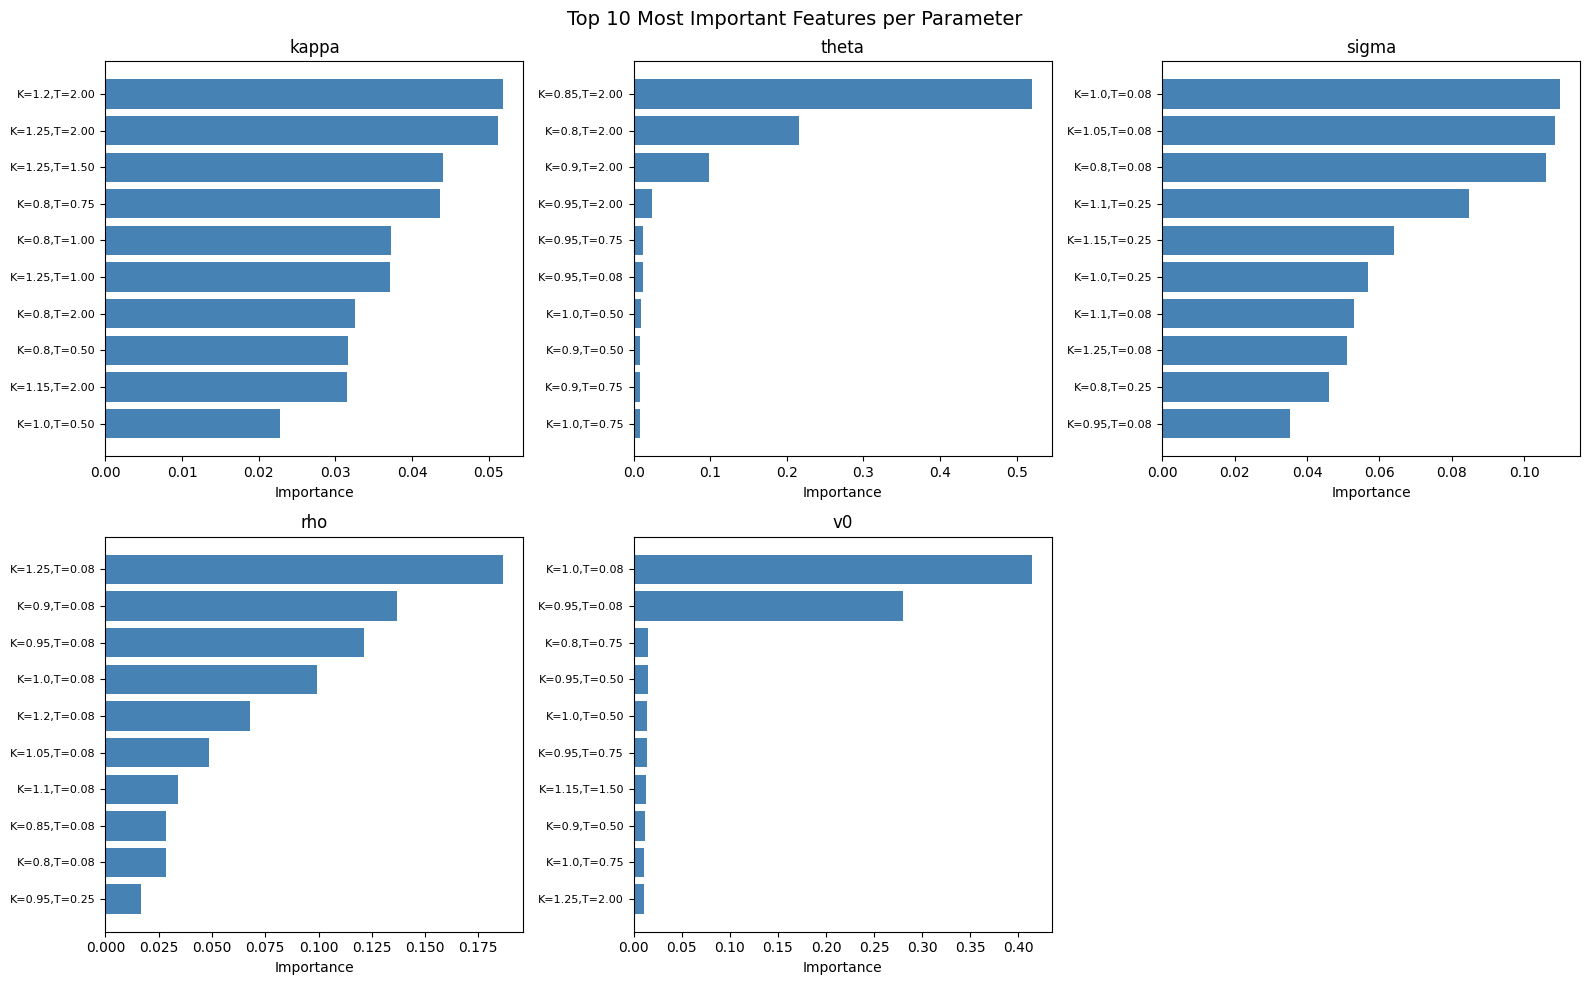

Saved: feature_importance.png


In [17]:
# ============================================
# FEATURE IMPORTANCE PLOT
# ============================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Create labels for the 70 features (strike x maturity combinations)
feature_labels = []
for T in maturities:
    for m in moneyness:
        feature_labels.append(f"K={m},T={T:.2f}")

for i, name in enumerate(param_names):
    ax = axes[i]
    
    # Get top 10 most important features
    importance = models[name].feature_importances_
    top_10_idx = np.argsort(importance)[-10:]
    top_10_imp = importance[top_10_idx]
    top_10_labels = [feature_labels[idx] for idx in top_10_idx]
    
    ax.barh(range(10), top_10_imp, color='steelblue')
    ax.set_yticks(range(10))
    ax.set_yticklabels(top_10_labels, fontsize=8)
    ax.set_title(f'{name}')
    ax.set_xlabel('Importance')

axes[5].set_visible(False)
plt.suptitle('Top 10 Most Important Features per Parameter', fontsize=14)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()
print("Saved: feature_importance.png")

In [18]:
# ============================================
# FINAL SUMMARY TABLE FOR THESIS
# ============================================

print("=" * 65)
print("TABLE 1: XGBoost Parameter Prediction Accuracy (Test Set)")
print("=" * 65)
print(f"{'Parameter':<12} {'Range':<16} {'MAE':<10} {'MSE':<12} {'R²':<8}")
print("-" * 65)
ranges = {
    'kappa': '[0.5, 10.0]',
    'theta': '[0.01, 0.15]',
    'sigma': '[0.1, 1.0]',
    'rho':   '[-0.95, -0.1]',
    'v0':    '[0.01, 0.15]'
}
for name in param_names:
    metrics = results[name]
    print(f"{name:<12} {ranges[name]:<16} {metrics['MAE']:<10.4f} {metrics['MSE']:<12.6f} {metrics['R2']:<8.4f}")
print("=" * 65)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]} implied volatilities")

print("\n")
print("=" * 65)
print("TABLE 2: Calibration Method Comparison")
print("=" * 65)
print(f"{'Method':<30} {'Avg RMSE':<15} {'Avg Time':<15}")
print("-" * 65)
print(f"{'Heston (XGBoost)':<30} {np.nanmean(xgb_rmses):<15.4f} {np.mean(xgb_times)*1000:<10.2f} ms")
print(f"{'Heston (Differential Evol.)':<30} {np.mean(trad_errors):<15.4f} {np.mean(trad_times):<10.2f} s")
print("=" * 65)
print(f"\nXGBoost is {np.mean(trad_times)/np.mean(xgb_times):.0f}x faster, "
      f"with an average surface RMSE of {np.nanmean(xgb_rmses):.4f} "
      f"vs {np.mean(trad_errors):.4f} for traditional calibration.")


TABLE 1: XGBoost Parameter Prediction Accuracy (Test Set)
Parameter    Range            MAE        MSE          R²      
-----------------------------------------------------------------
kappa        [0.5, 10.0]      0.5521     0.610134     0.9167  
theta        [0.01, 0.15]     0.0013     0.000008     0.9949  
sigma        [0.1, 1.0]       0.0290     0.001434     0.9791  
rho          [-0.95, -0.1]    0.0346     0.003339     0.9444  
v0           [0.01, 0.15]     0.0008     0.000001     0.9992  

Training samples: 13932
Test samples: 2984
Features: 70 implied volatilities


TABLE 2: Calibration Method Comparison
Method                         Avg RMSE        Avg Time       
-----------------------------------------------------------------
Heston (XGBoost)               0.0026          9.03       ms
Heston (Differential Evol.)    0.0000          2404.81    s

XGBoost is 266430x faster, with an average surface RMSE of 0.0026 vs 0.0000 for traditional calibration.
